In [2]:
import os

import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch
import seaborn as sns

from statsmodels.tsa.api import VAR

from tv_var.harmonic_standardizer import HarmonicStandardizer

In [3]:
#### Load Data
path_pcs = os.path.join("..", "..", "inputs", "pcs_df.csv")
pcs_df = pd.read_csv(path_pcs, index_col=0, parse_dates=True)

#### Inputs
n_harmonics = 3

#### Path_outputs
name_model = f'var_zs_nh_{n_harmonics}'
path_output = os.path.join("..", "..", "outputs", "model_comp", f"{name_model}.nc")

In [4]:
harm_std = HarmonicStandardizer(n_harmonics=n_harmonics)

In [5]:
harm_std.fit(pcs_df)
zs_df = harm_std.transform(pcs_df)

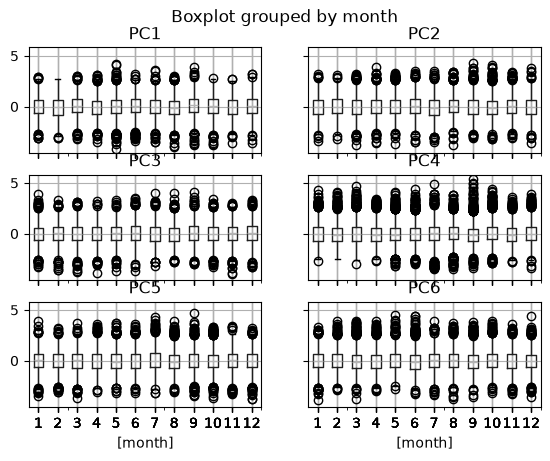

In [6]:
zs_df['month'] = zs_df.index.month
zs_df.boxplot(by='month')
zs_df = zs_df.drop(columns='month')

In [7]:
var_model = VAR(zs_df, freq='D')
results = var_model.fit(maxlags=7, ic='aic', trend='c')

In [8]:
results.is_stable()

np.True_

In [9]:
best_lag = results.k_ar
print(f'Best_lag = {best_lag}')

Best_lag = 7


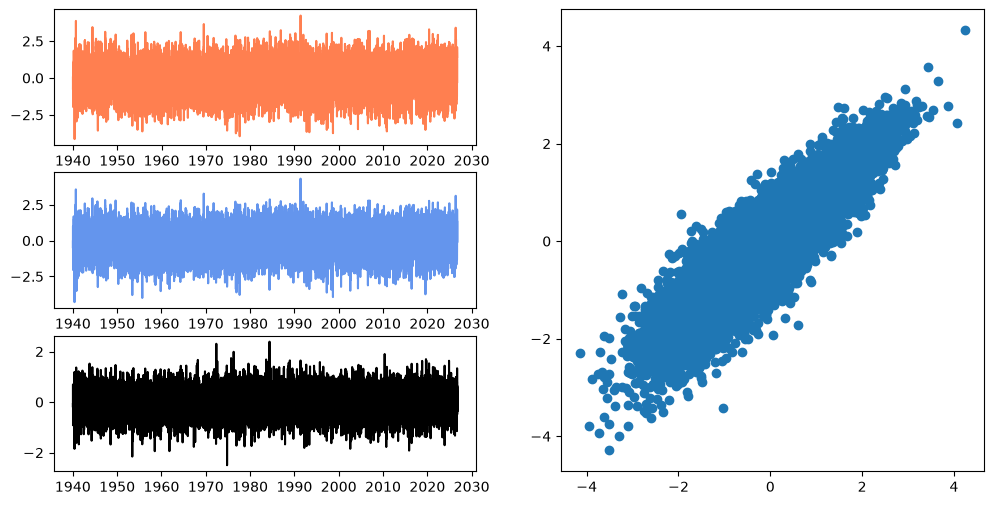

In [10]:
# Create a figure
fig = plt.figure(figsize=(12,6))

# Create a GridSpec with 2 rows and 2 columns
gs = GridSpec(3, 2)

# Add subplots to the grid
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[2, 0])
ax4 = fig.add_subplot(gs[:, 1])


ax1.plot(zs_df['PC1'], color='coral')
ax2.plot(results.fittedvalues['PC1'], color='cornflowerblue')
ax3.plot(results.resid['PC1'], color = 'k')

ax4.scatter(zs_df['PC1'].values[best_lag:],results.fittedvalues['PC1'].values)

In [11]:
from sklearn.metrics import r2_score

pcs_list = zs_df.columns.to_list()

for col in pcs_list:
    r2 = r2_score(zs_df[col][results.fittedvalues.index], results.fittedvalues[col])
    print(f'r2 score for {col} = {r2}')

r2 score for PC1 = 0.8204049800543665
r2 score for PC2 = 0.7493762280765981
r2 score for PC3 = 0.6456714862575033
r2 score for PC4 = 0.5910532036326914
r2 score for PC5 = 0.40850714379711894
r2 score for PC6 = 0.429855427965813


#### Predict

In [12]:
n_sims = 100

burn  = 365
dates = pcs_df.index                                  # ERA5 calendar for the evaluation runs

simulations_list = []
for sim_idx in range(n_sims):
    z = results.simulate_var(steps=burn + len(dates), rng=sim_idx)[burn:]   # drop the warm-up
    z_df = pd.DataFrame(z, columns=pcs_df.columns, index=dates)
    simulations_list.append(harm_std.inverse_transform(z_df))

/nfs/home/geocean/alonsoap/.conda/envs/tv_var/lib/python3.12/site-packages/statsmodels/tsa/vector_ar/var_model.py:1061: FutureWarning: After statsmodels 0.15 is released, passing an integer whencreating a random number generator will pass the value to np.random.default_rng, rather than the current behavior of passing it to np.random.RandomState. To continue using RandomState, directly pass a RandomState instance.
  rng = check_random_state(rng, deprecated=True)
/nfs/home/geocean/alonsoap/.conda/envs/tv_var/lib/python3.12/site-packages/statsmodels/tsa/vector_ar/var_model.py:1061: FutureWarning: After statsmodels 0.15 is released, passing an integer whencreating a random number generator will pass the value to np.random.default_rng, rather than the current behavior of passing it to np.random.RandomState. To continue using RandomState, directly pass a RandomState instance.
  rng = check_random_state(rng, deprecated=True)
/nfs/home/geocean/alonsoap/.conda/envs/tv_var/lib/python3.12/site-pa

In [13]:
simulations_list_xr = [df.to_xarray() for df in simulations_list]

sim = xr.concat(simulations_list_xr, dim='seed')
sim = sim.to_array('pc').rename({'index': 'time'}).transpose('seed', 'time', 'pc').rename('pcs')
sim.to_netcdf(path_output)

In [14]:
sim_0_df = sim.isel(seed=0).to_pandas()

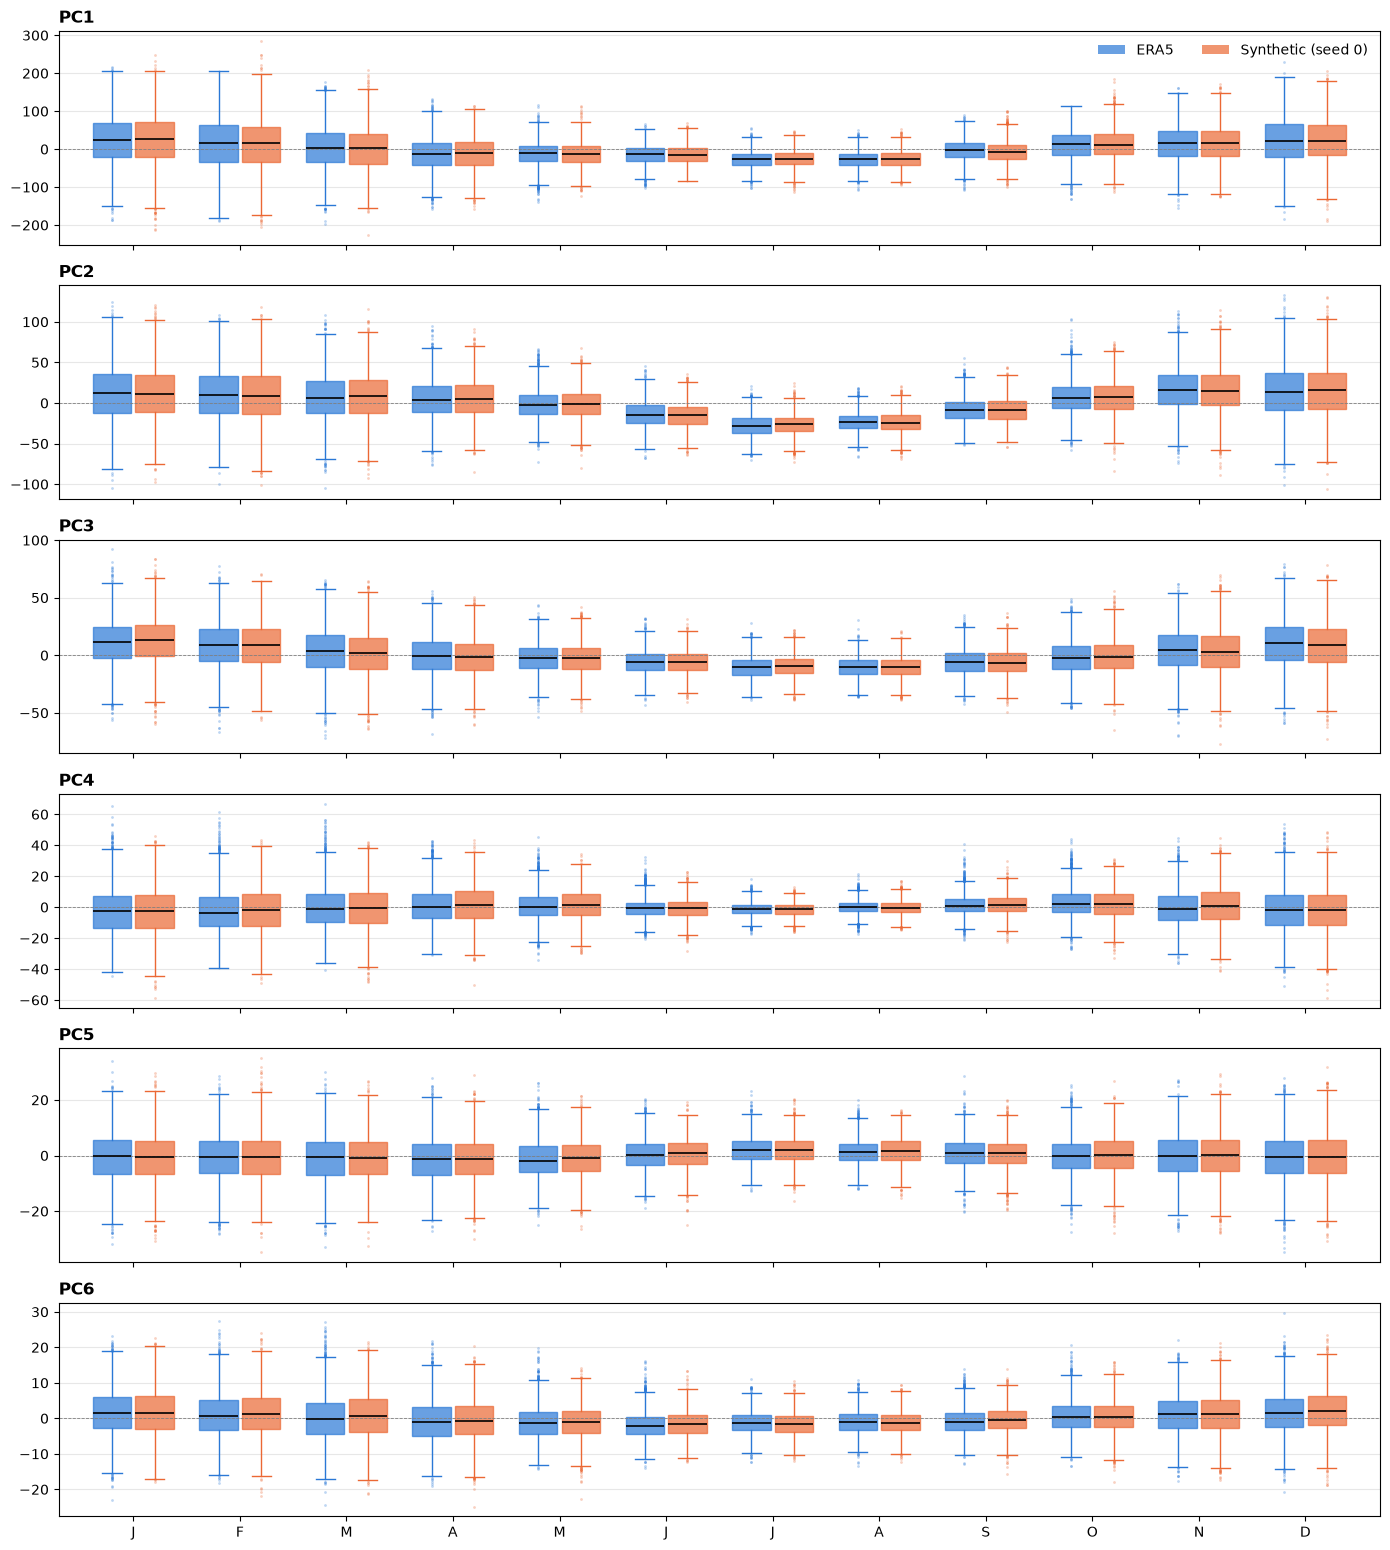

In [15]:
def monthly_boxplots(dfs, colors, pcs=None):
    """dfs: {label: DataFrame with DatetimeIndex}. One row per PC, boxes side by side per month."""
    pcs    = pcs or list(next(iter(dfs.values())).columns)
    months = np.arange(1, 13)
    n      = len(dfs)
    width  = 0.8 / n

    fig, axes = plt.subplots(len(pcs), 1, figsize=(14, 2.6 * len(pcs)), sharex=True)
    for ax, pc in zip(np.atleast_1d(axes), pcs):
        for i, (label, df) in enumerate(dfs.items()):
            data = [df.loc[df.index.month == m, pc].values for m in months]
            pos  = months - 0.4 + width * (i + 0.5)
            bp = ax.boxplot(data, positions=pos, widths=width * 0.9, patch_artist=True,
                            flierprops=dict(marker=".", markersize=2, alpha=0.3,
                                            markeredgecolor=colors[label]),
                            medianprops=dict(color="black", lw=1.2),
                            whiskerprops=dict(color=colors[label]),
                            capprops=dict(color=colors[label]))
            for box in bp["boxes"]:
                box.set(facecolor=colors[label], alpha=0.7, edgecolor=colors[label])
        ax.set_title(pc, loc="left", fontweight="bold")
        ax.axhline(0, color="grey", lw=0.6, ls="--")
        ax.grid(axis="y", alpha=0.3)
    axes[-1].set_xticks(months)
    axes[-1].set_xticklabels(list("JFMAMJJASOND"))
    axes[0].legend(handles=[Patch(facecolor=c, alpha=0.7, label=l) for l, c in colors.items()],
                   loc="upper right", ncol=n, frameon=False)
    fig.tight_layout()
    return fig

monthly_boxplots({"ERA5": pcs_df, "Synthetic (seed 0)": sim_0_df},
                 colors={"ERA5": "#2a78d6", "Synthetic (seed 0)": "#eb6834"})
plt.show()

#### Autocorrelations Per Month

In [21]:
pcs_list = pcs_df.columns.to_list()

auto_corr = {}

for pc in pcs_list:
    era5_aux_df = pcs_df[[pc]].copy()
    for i in range(1,11,1):
        era5_aux_df[f'{pc}_lag_{i}']= era5_aux_df[pc].shift(i)

    era5_aux_df['month'] = era5_aux_df.index.month
    for month in range(1,13,1):
        aux_df = era5_aux_df[era5_aux_df['month'] == month].copy()
        aux_df = aux_df.drop(columns='month')
        auto_corr[f'{pc}_month_{month}'] = aux_df.corr().values[:,0]

In [23]:
def acf_by_month(df, max_lag=10):
    """{f'{pc}_month_{m}': [1, r1, ..., r_max_lag]} on the given (standardized) data."""
    auto_corr = {}
    for pc in df.columns:
        era5_aux_df = df[[pc]].copy()
        for i in range(1, max_lag + 1):
            era5_aux_df[f'{pc}_lag_{i}'] = era5_aux_df[pc].shift(i)

        era5_aux_df['month'] = era5_aux_df.index.month
        for month in range(1, 13):
            aux_df = era5_aux_df[era5_aux_df['month'] == month].drop(columns='month')
            auto_corr[f'{pc}_month_{month}'] = aux_df.corr().values[:, 0]
    return auto_corr

zs_df   = harm_std.transform(pcs_df)            # ERA5 on z
acf_obs = acf_by_month(zs_df)

acf_sims = [acf_by_month(harm_std.transform(sim.isel(seed=s).to_pandas()))
            for s in range(sim.sizes["seed"])]

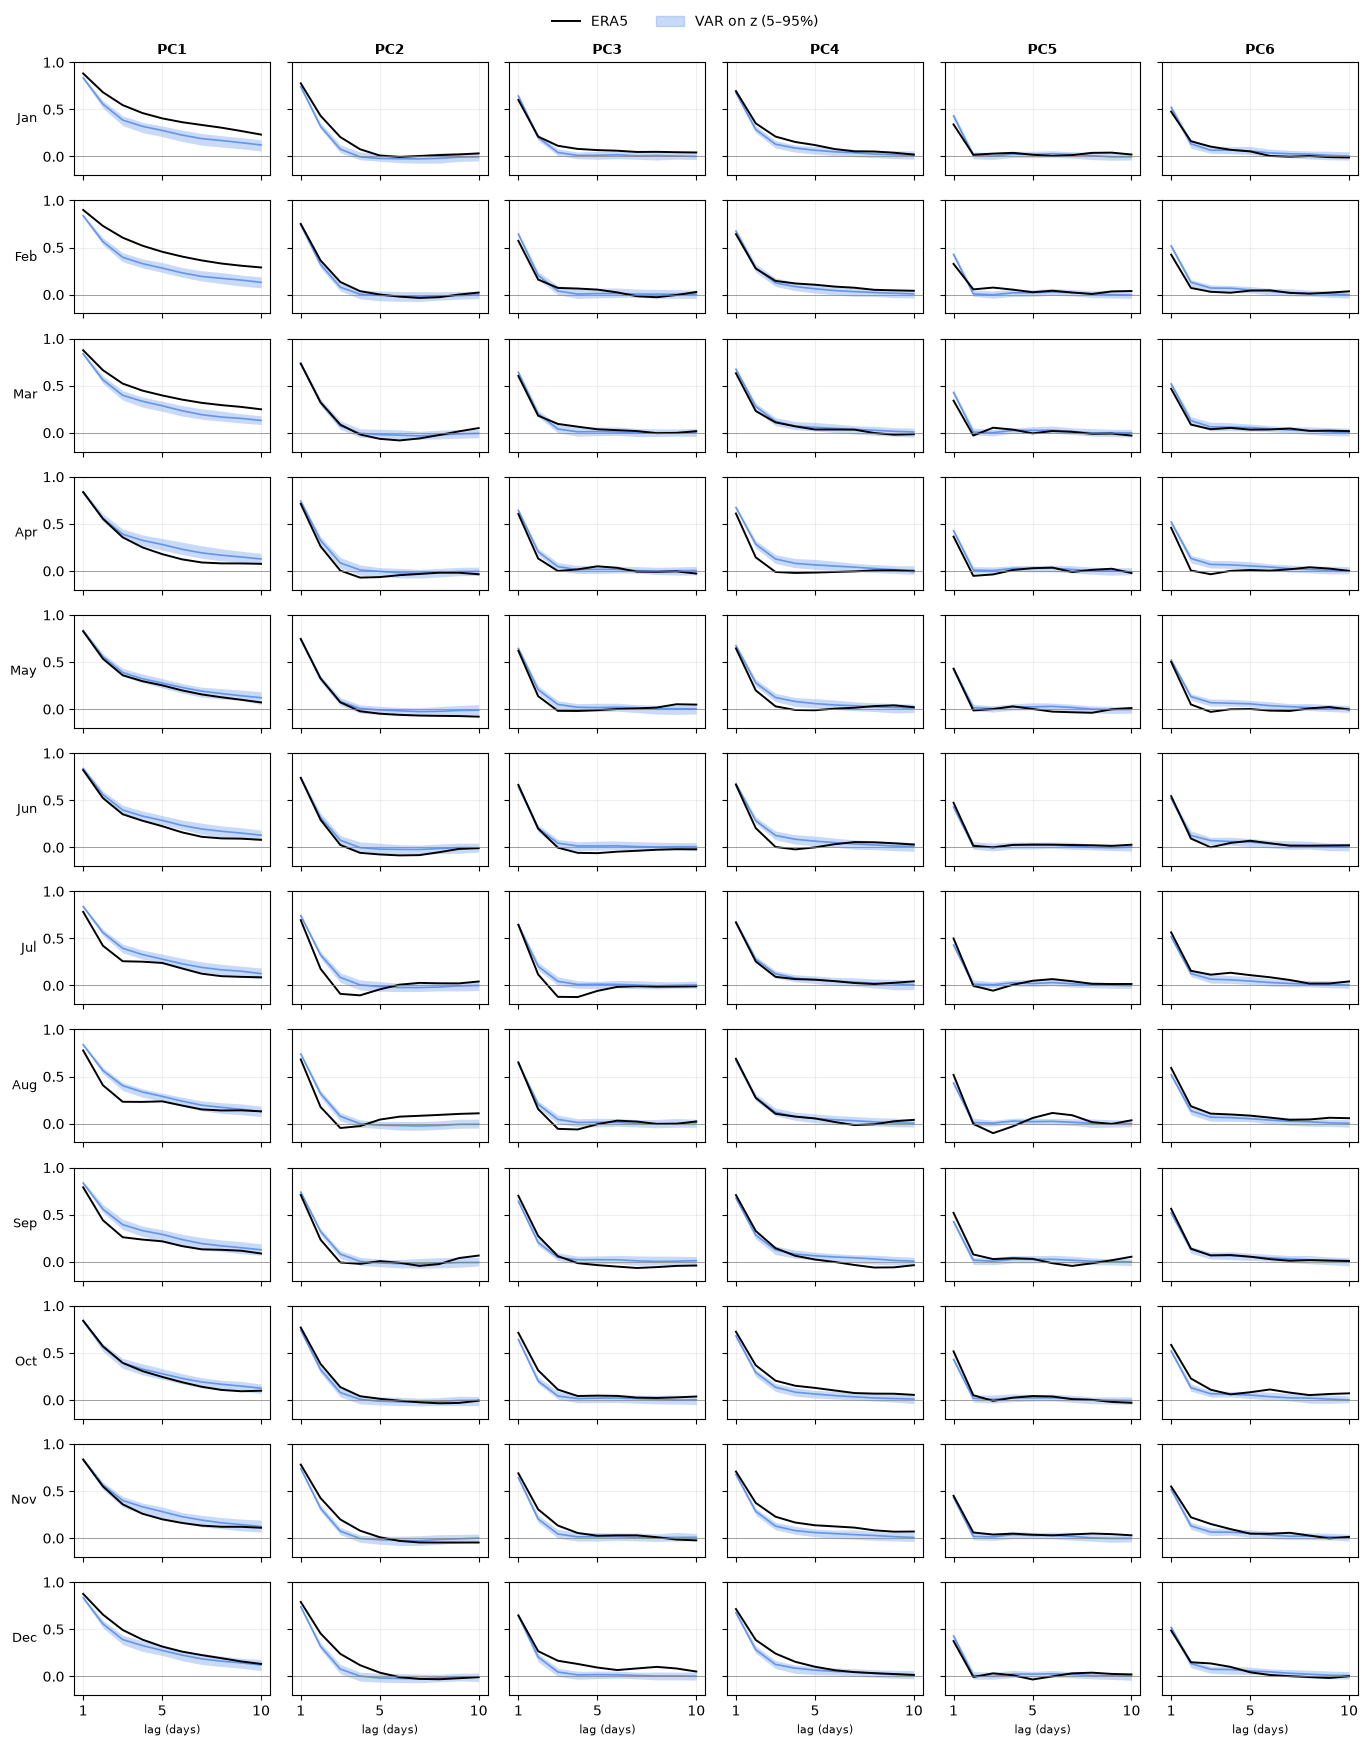

In [31]:
months = range(1, 13)
lags   = np.arange(1, 11)
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, axes = plt.subplots(12, len(pcs_list), figsize=(2.3 * len(pcs_list), 1.45 * 12),
                         sharex=True, sharey=True)

for i, m in enumerate(months):
    for j, pc in enumerate(pcs_list):
        ax  = axes[i, j]
        key = f'{pc}_month_{m}'
        sim = np.array([a[key][1:] for a in acf_sims])          # records x lags (drop lag 0)
        lo, hi = np.percentile(sim, [5, 95], axis=0)

        ax.fill_between(lags, lo, hi, color="cornflowerblue", alpha=0.35, lw=0)
        ax.plot(lags, np.median(sim, axis=0), color="cornflowerblue", lw=1.2)
        ax.plot(lags, acf_obs[key][1:], color="black", lw=1.4)
        ax.axhline(0, color="grey", lw=0.5)
        ax.grid(alpha=0.2)

        if i == 0:  ax.set_title(pc, fontsize=10, fontweight="bold")
        if j == 0:  ax.set_ylabel(month_names[m - 1], fontsize=9, rotation=0, ha="right", va="center")

axes[0, 0].set_ylim(-0.2, 1.0)
axes[0, 0].set_xticks([1, 5, 10])
for ax in axes[-1]: ax.set_xlabel("lag (days)", fontsize=8)

handles = [plt.Line2D([], [], color="black", lw=1.4, label="ERA5"),
           plt.Rectangle((0, 0), 1, 1, color="cornflowerblue", alpha=0.35, label="VAR on z (5–95%)")]
fig.legend(handles=handles, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.005))
fig.tight_layout(rect=(0, 0, 1, 0.99))
plt.show()